# sizerec: Hybrid Matrix Factorization cho gợi ý size thời trang

**Đề tài:** Sử dụng Machine Learning (Matrix Factorization kết hợp thông số cơ thể tự kê khai) để dự đoán kích cỡ phù hợp nhất cho người mua, nhằm giảm tỉ lệ trả hàng do lệch size.

Notebook này minh hoạ toàn bộ quy trình thực nghiệm:
1. Đọc và thống kê dữ liệu ModCloth, RentTheRunway
2. Chạy thử một thực nghiệm nhanh
3. Kết quả đầy đủ (10 seed, 2 giao thức) và kiểm định thống kê
4. Đánh giá đề xuất size
5. Demo gợi ý size cho khách mới và khách cũ

Chạy từ thư mục `03-code/notebooks`. Cần cài gói trước: `pip install -r ../requirements.txt && pip install -e ..`

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(".."))          # dùng gói sizerec trong 03-code
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

DATA = os.path.join("..", "..", "02-data")
RES = os.path.join("..", "..", "04-results")
MC = os.path.join(DATA, "modcloth_final_data.json.gz")
RTR = os.path.join(DATA, "renttherunway_final_data.json.gz")
pd.set_option("display.precision", 4)
import sizerec; print("sizerec", sizerec.__version__)

sizerec 1.0.0


## 1. Dữ liệu

Đọc dữ liệu, làm sạch, chuẩn hoá đơn vị và loại các trường chỉ có sau khi mua (review, rating, quality, length) để tránh rò rỉ dữ liệu.

In [2]:
from sizerec.data import load_dataset
datasets = {"ModCloth": load_dataset(MC), "RentTheRunway": load_dataset(RTR)}
rows = []
for name, d in datasets.items():
    df = d.df
    rows.append({"Bộ dữ liệu": name, "Giao dịch": len(df), "Người dùng": df.user_id.nunique(),
                 "Sản phẩm": df.item_id.nunique(), "Danh mục": df.category.nunique(),
                 "Tỉ lệ user 1 giao dịch": (df.user_id.value_counts() == 1).mean()})
pd.DataFrame(rows).set_index("Bộ dữ liệu")

,Giao dịch,Người dùng,Sản phẩm,Danh mục,Tỉ lệ user 1 giao dịch
Bộ dữ liệu,,,,,
ModCloth,82790,47958,1378,7,0.6645
RentTheRunway,192544,105571,5850,68,0.6803


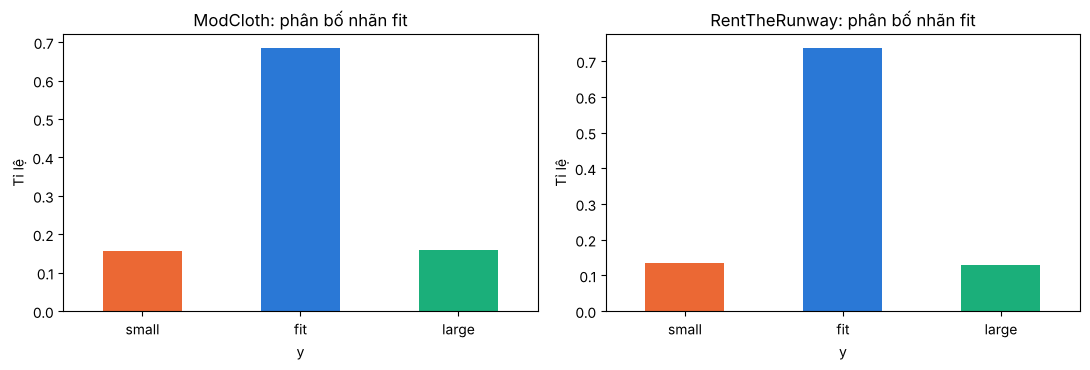

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (name, d) in zip(axes, datasets.items()):
    d.df["y"].map({0: "small", 1: "fit", 2: "large"}).value_counts(normalize=True)[["small", "fit", "large"]].plot.bar(ax=ax, color=["#eb6834", "#2a78d6", "#1baf7a"], rot=0)
    ax.set_title(f"{name}: phân bố nhãn fit"); ax.set_ylabel("Tỉ lệ")
plt.tight_layout(); plt.show()

In [4]:
# Tỉ lệ thiếu từng số đo cơ thể tự khai
pd.DataFrame({name: d.body.isna().mean() for name, d in datasets.items()}).round(3)

,ModCloth,RentTheRunway
age,NaN,0.005
bmi,NaN,0.158
bust,0.857,NaN
bust_band,0.073,0.096
cup,0.076,0.096
height,0.014,0.004
hips,0.323,NaN
shoe,0.663,NaN
waist,0.965,NaN
weight,NaN,0.156


## 2. Chạy thử một thực nghiệm nhanh

Giao thức cold-start (người dùng trong tập test chưa từng xuất hiện), 1 seed, 7 mô hình. Lệnh tương đương trên dòng lệnh: `sizerec experiment ../02-data/modcloth_final_data.json.gz --quick`.

In [5]:
import subprocess
out = os.path.abspath(os.path.join(RES, "quick", "modcloth_notebook"))
r = subprocess.run([sys.executable, "-m", "sizerec", "--no-color", "experiment", os.path.abspath(MC), "--quick", "-o", out],
                   cwd="..", capture_output=True, text=True, env={**os.environ, "COLUMNS": "120", "PYTHONUTF8": "1"})
print((r.stdout[-2500:] or r.stderr[-2500:]).replace(out, os.path.relpath(out)))

0m    0.6728 ± 0.0000     0.4763   0.6192  
                                                                 
 Kiểm định: mf_body_product ★ so với từng mô hình (paired bootstrap + paired t-test theo seed) 
                                                                                               
  Nhóm       So với                      ΔAUC             CI 95%   p boot   p t-test   p<0.05  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  cold/all   majority                 +0.1717   [+0.158, +0.181]   <0.020          —   có      
  cold/all   body_lr                  +0.0895   [+0.080, +0.101]   <0.020          —   có      
  cold/all   mf                       +0.0185   [+0.013, +0.024]   <0.020          —   có      
  cold/all   mf_body                  +0.0051   [-0.000, +0.009]    0.080          —   không   
  cold/all   body_product             +0.0066   [+0.001, +0.011]   <0.020          —   có      
  cold/all   mf_body_produ

## 3. Kết quả đầy đủ: 10 seed, 2 giao thức

Kết quả đã chạy bằng `scripts/run_all.sh` được lưu trong `04-results/experiment/`. Mô hình đề xuất là `mf_body_product`.

In [6]:
order = ["majority", "body_lr", "mf", "mf_body", "body_product", "mf_body_product", "mf_body_product_nodrop"]
def summary(ds):
    s = pd.read_csv(os.path.join(RES, "experiment", ds, "summary.csv"))
    s = s[s.bucket == "all"].pivot_table(index="model", columns="protocol", values=["auc_mean", "macro_f1_mean"])
    return s.reindex(order).round(4)
display(Markdown("**ModCloth**")); display(summary("modcloth"))
display(Markdown("**RentTheRunway**")); display(summary("rtr"))

**ModCloth**

auc_mean         macro_f1_mean        
protocol                   cold    warm          cold    warm
model                                                        
majority                 0.5000  0.5000        0.2707  0.2718
body_lr                  0.5845  0.5834        0.3793  0.3780
mf                       0.6610  0.6631        0.4504  0.4224
mf_body                  0.6743  0.6753        0.4784  0.4842
body_product             0.6776  0.6750        0.4858  0.4788
mf_body_product          0.6790  0.6823        0.4862  0.4916
mf_body_product_nodrop   0.6793  0.6819        0.4866  0.4868

**RentTheRunway**

auc_mean         macro_f1_mean        
protocol                   cold    warm          cold    warm
model                                                        
majority                 0.5000  0.5000        0.2829  0.2830
body_lr                  0.6195  0.6197        0.4209  0.4241
mf                       0.7220  0.7245        0.5022  0.4735
mf_body                  0.7241  0.7268        0.5307  0.5316
body_product             0.7289  0.7302        0.5240  0.5281
mf_body_product          0.7305  0.7358        0.5348  0.5450
mf_body_product_nodrop   0.7309  0.7354        0.5353  0.5418

In [7]:
# AUC theo số giao dịch lịch sử của người dùng (giao thức warm)
for ds in ["modcloth", "rtr"]:
    s = pd.read_csv(os.path.join(RES, "experiment", ds, "summary.csv"))
    t = s[(s.protocol == "warm") & s.model.isin(["mf", "mf_body", "body_product", "mf_body_product"])]
    display(Markdown(f"**{ds}**")); display(t.pivot_table(index="model", columns="bucket", values="auc_mean")[["0", "1", "2-4", "5+", "all"]].round(4))

**modcloth**

bucket,0,1,2-4,5+,all
model,,,,,
body_product,0.6749,0.6743,0.6715,0.6848,0.6750
mf,0.6581,0.6694,0.6630,0.6706,0.6631
mf_body,0.6713,0.6760,0.6755,0.6890,0.6753
mf_body_product,0.6767,0.6808,0.6862,0.6981,0.6823


**rtr**

bucket,0,1,2-4,5+,all
model,,,,,
body_product,0.7337,0.7286,0.7319,0.7211,0.7302
mf,0.7278,0.7229,0.7257,0.7215,0.7245
mf_body,0.7255,0.7249,0.7297,0.7267,0.7268
mf_body_product,0.7350,0.7327,0.7390,0.7351,0.7358


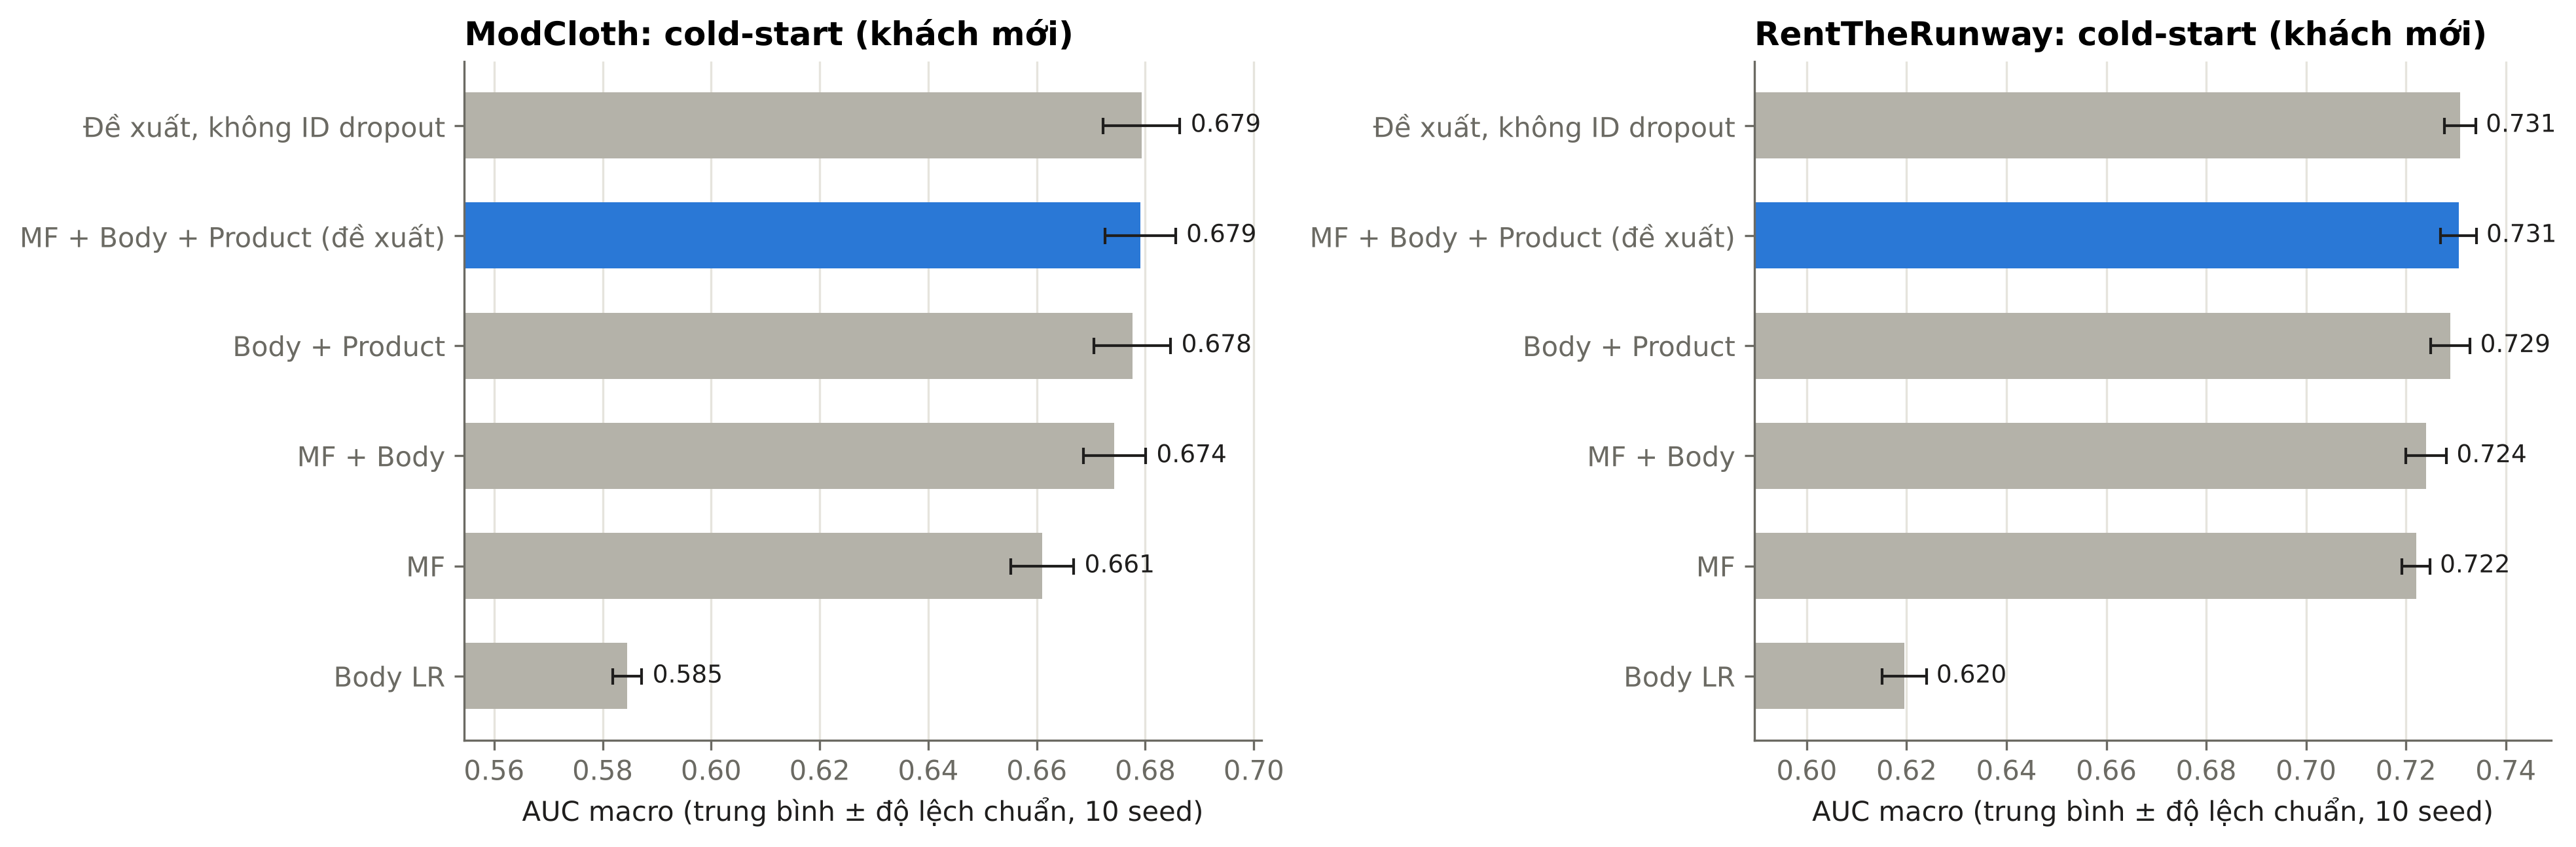

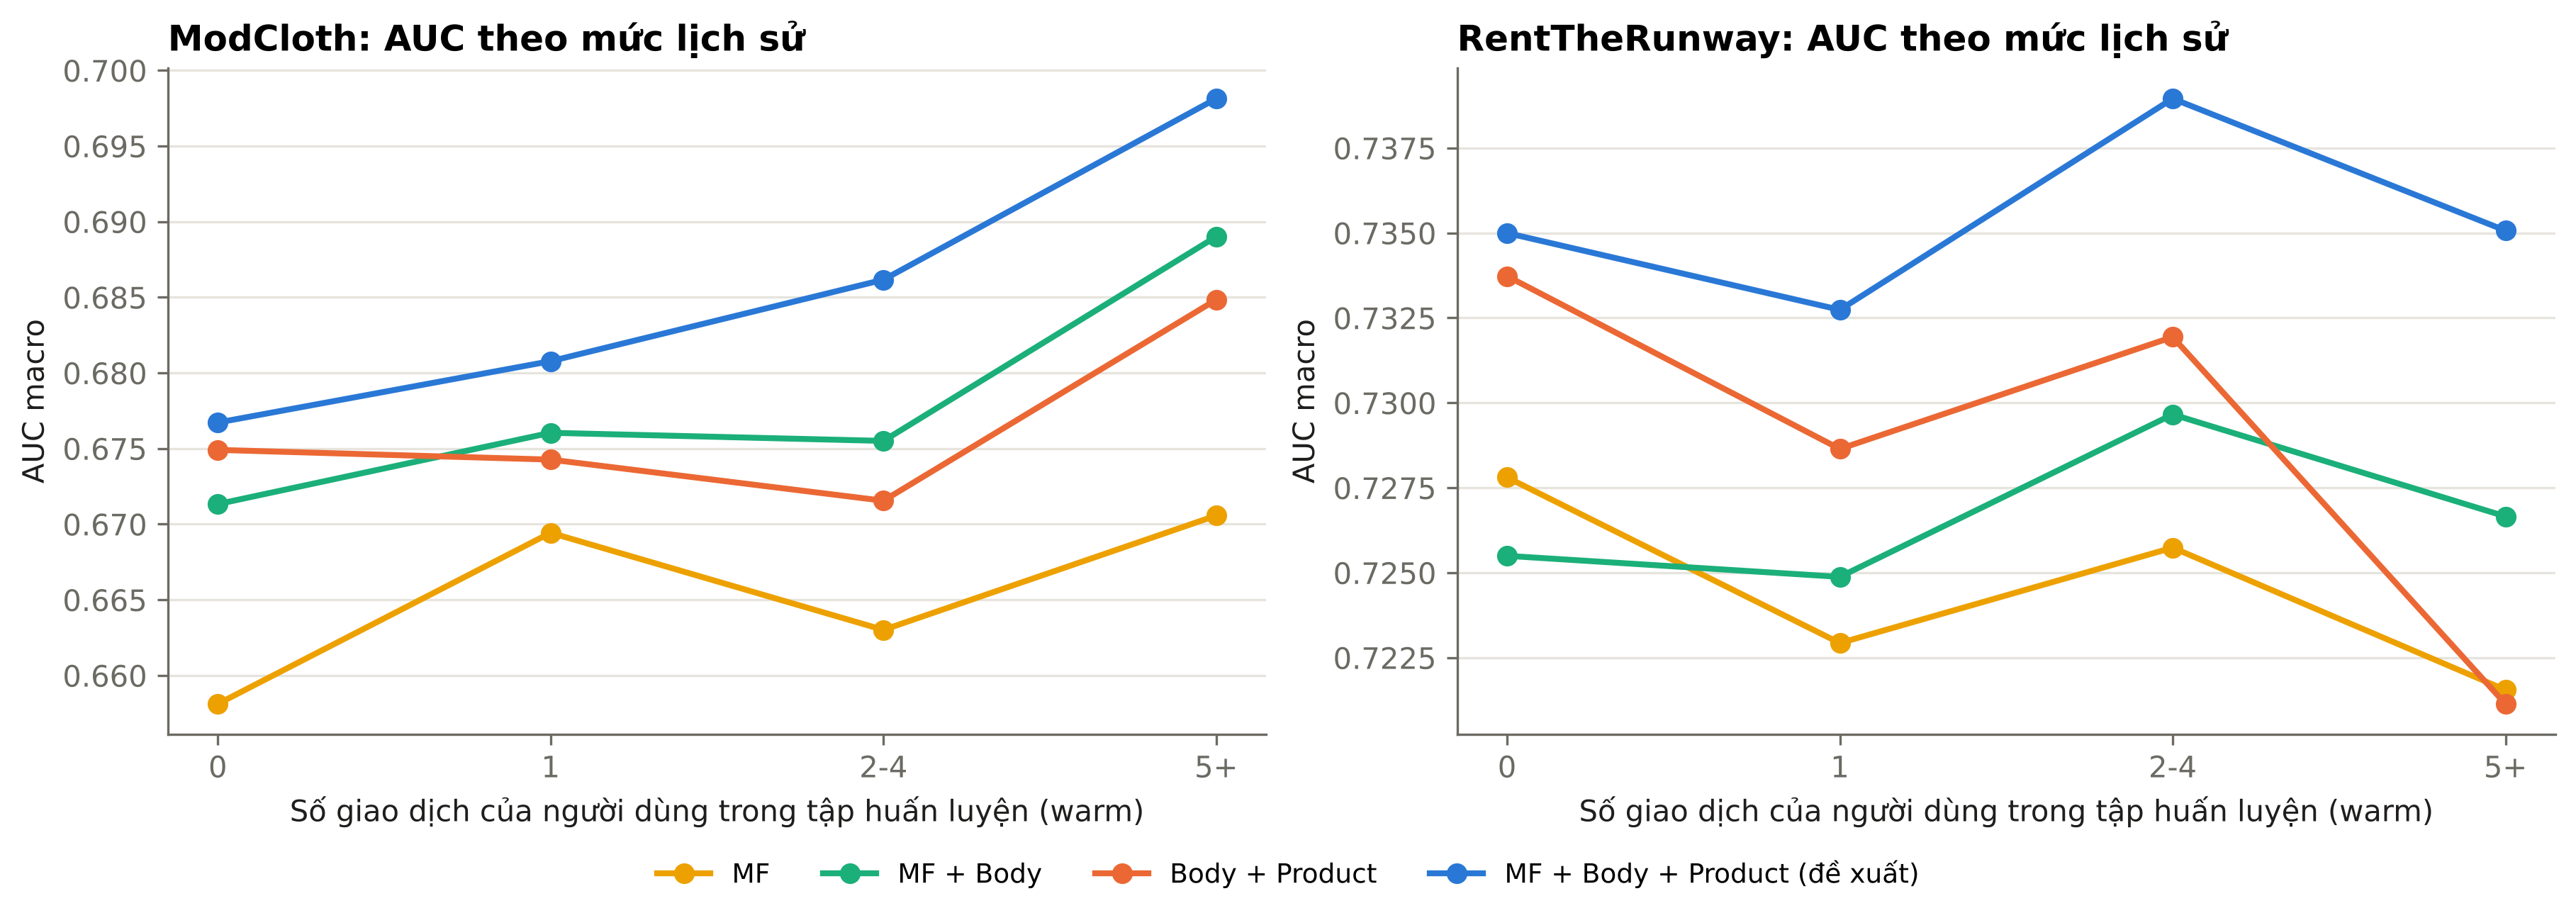

In [8]:
display(Image(os.path.join(RES, "figures", "fig2_auc_cold_start.png"), width=900))
display(Image(os.path.join(RES, "figures", "fig3_auc_by_history.png"), width=900))

### Boxplot AUC qua 10 lần lặp

Mỗi điểm là AUC trên tập test của một lần lặp (một seed, tức một cách chia dữ liệu khác nhau). Hộp càng hẹp thì kết quả càng ổn định; mô hình đề xuất tô màu xanh.

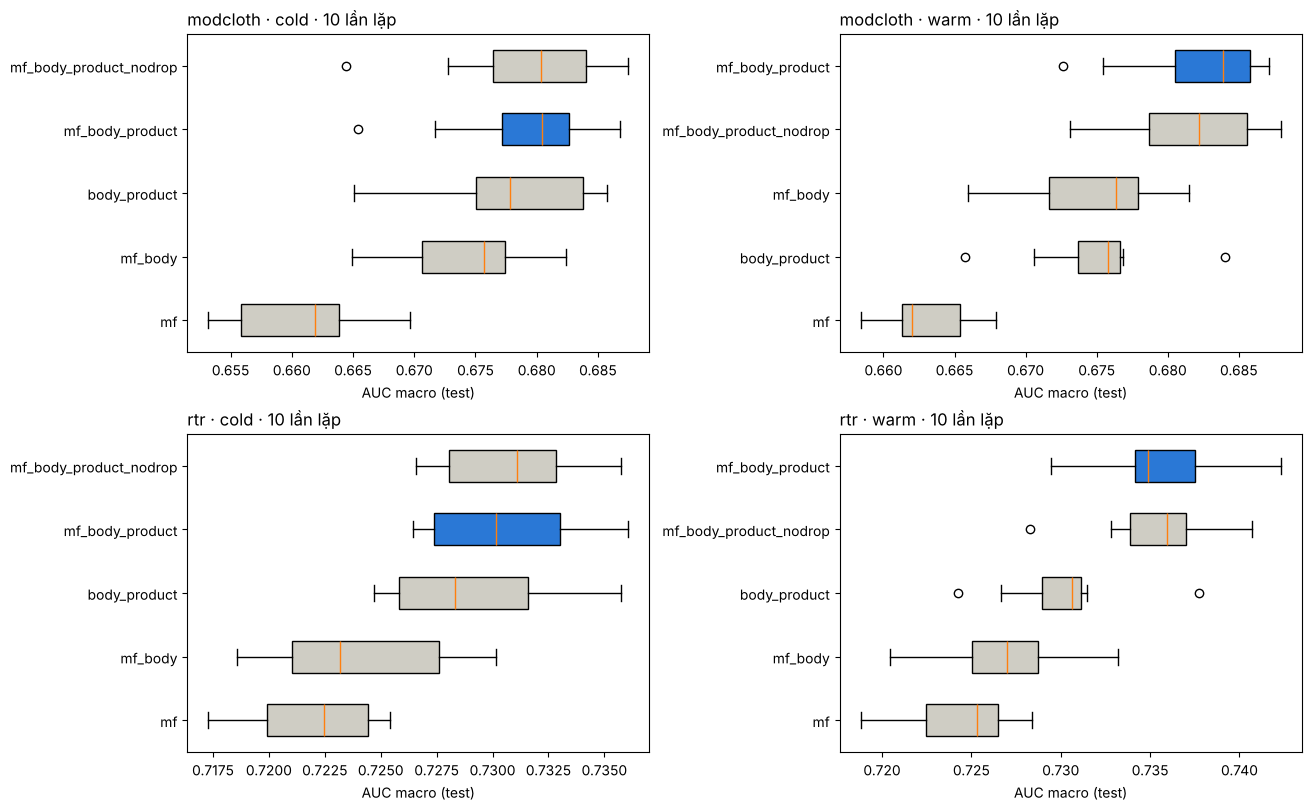

In [9]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout="constrained")
for r, ds in enumerate(["modcloth", "rtr"]):
    per = pd.read_csv(os.path.join(RES, "experiment", ds, "metrics_per_seed.csv"))
    for c, proto in enumerate(["cold", "warm"]):
        t = per[(per.protocol == proto) & (per.bucket.astype(str) == "all") & ~per.model.isin(["majority", "body_lr"])]
        order = t.groupby("model").auc.mean().sort_values().index.tolist()
        bp = axes[r][c].boxplot([t[t.model == m].auc for m in order], orientation="horizontal", patch_artist=True, tick_labels=order)
        for patch, m in zip(bp["boxes"], order):
            patch.set_facecolor("#2a78d6" if m == "mf_body_product" else "#cfcdc4")
        axes[r][c].set_title(f"{ds} · {proto} · {t.seed.nunique()} lần lặp", loc="left")
        axes[r][c].set_xlabel("AUC macro (test)")
plt.show()

### Kiểm định thống kê

Paired bootstrap (200 lần) và paired t-test qua 10 seed: ΔAUC của mô hình đề xuất so với từng mô hình.

**modcloth**

,protocol,vs,delta_auc,ci95_low,ci95_high,p_bootstrap,p_ttest,significant
1,cold,body_lr,0.0945,0.0910,0.0985,0.00,0.0000,True
2,cold,mf,0.0180,0.0161,0.0203,0.00,0.0000,True
3,cold,mf_body,0.0047,0.0032,0.0063,0.00,0.0023,True
4,cold,body_product,0.0014,-0.0001,0.0030,0.08,0.2366,False
26,warm,body_lr,0.0989,0.0947,0.1021,0.00,0.0000,True
27,warm,mf,0.0191,0.0169,0.0215,0.00,0.0000,True
28,warm,mf_body,0.0069,0.0052,0.0084,0.00,0.0000,True
29,warm,body_product,0.0072,0.0053,0.0093,0.00,0.0005,True
30,cold,mf_body_product_nodrop,-0.0003,-0.0014,0.0008,0.60,0.7099,False
35,warm,mf_body_product_nodrop,0.0003,-0.0009,0.0019,0.68,0.7856,False


**rtr**

,protocol,vs,delta_auc,ci95_low,ci95_high,p_bootstrap,p_ttest,significant
1,cold,body_lr,0.1110,0.1086,0.1134,0.00,0.0000,True
2,cold,mf,0.0085,0.0071,0.0096,0.00,0.0000,True
3,cold,mf_body,0.0065,0.0052,0.0079,0.00,0.0000,True
4,cold,body_product,0.0016,0.0007,0.0026,0.00,0.0017,True
26,warm,body_lr,0.1161,0.1134,0.1184,0.00,0.0000,True
27,warm,mf,0.0114,0.0098,0.0126,0.00,0.0000,True
28,warm,mf_body,0.0090,0.0080,0.0103,0.00,0.0000,True
29,warm,body_product,0.0057,0.0046,0.0068,0.00,0.0000,True
30,cold,mf_body_product_nodrop,-0.0003,-0.0012,0.0006,0.46,0.5243,False
35,warm,mf_body_product_nodrop,0.0005,-0.0004,0.0013,0.28,0.3115,False


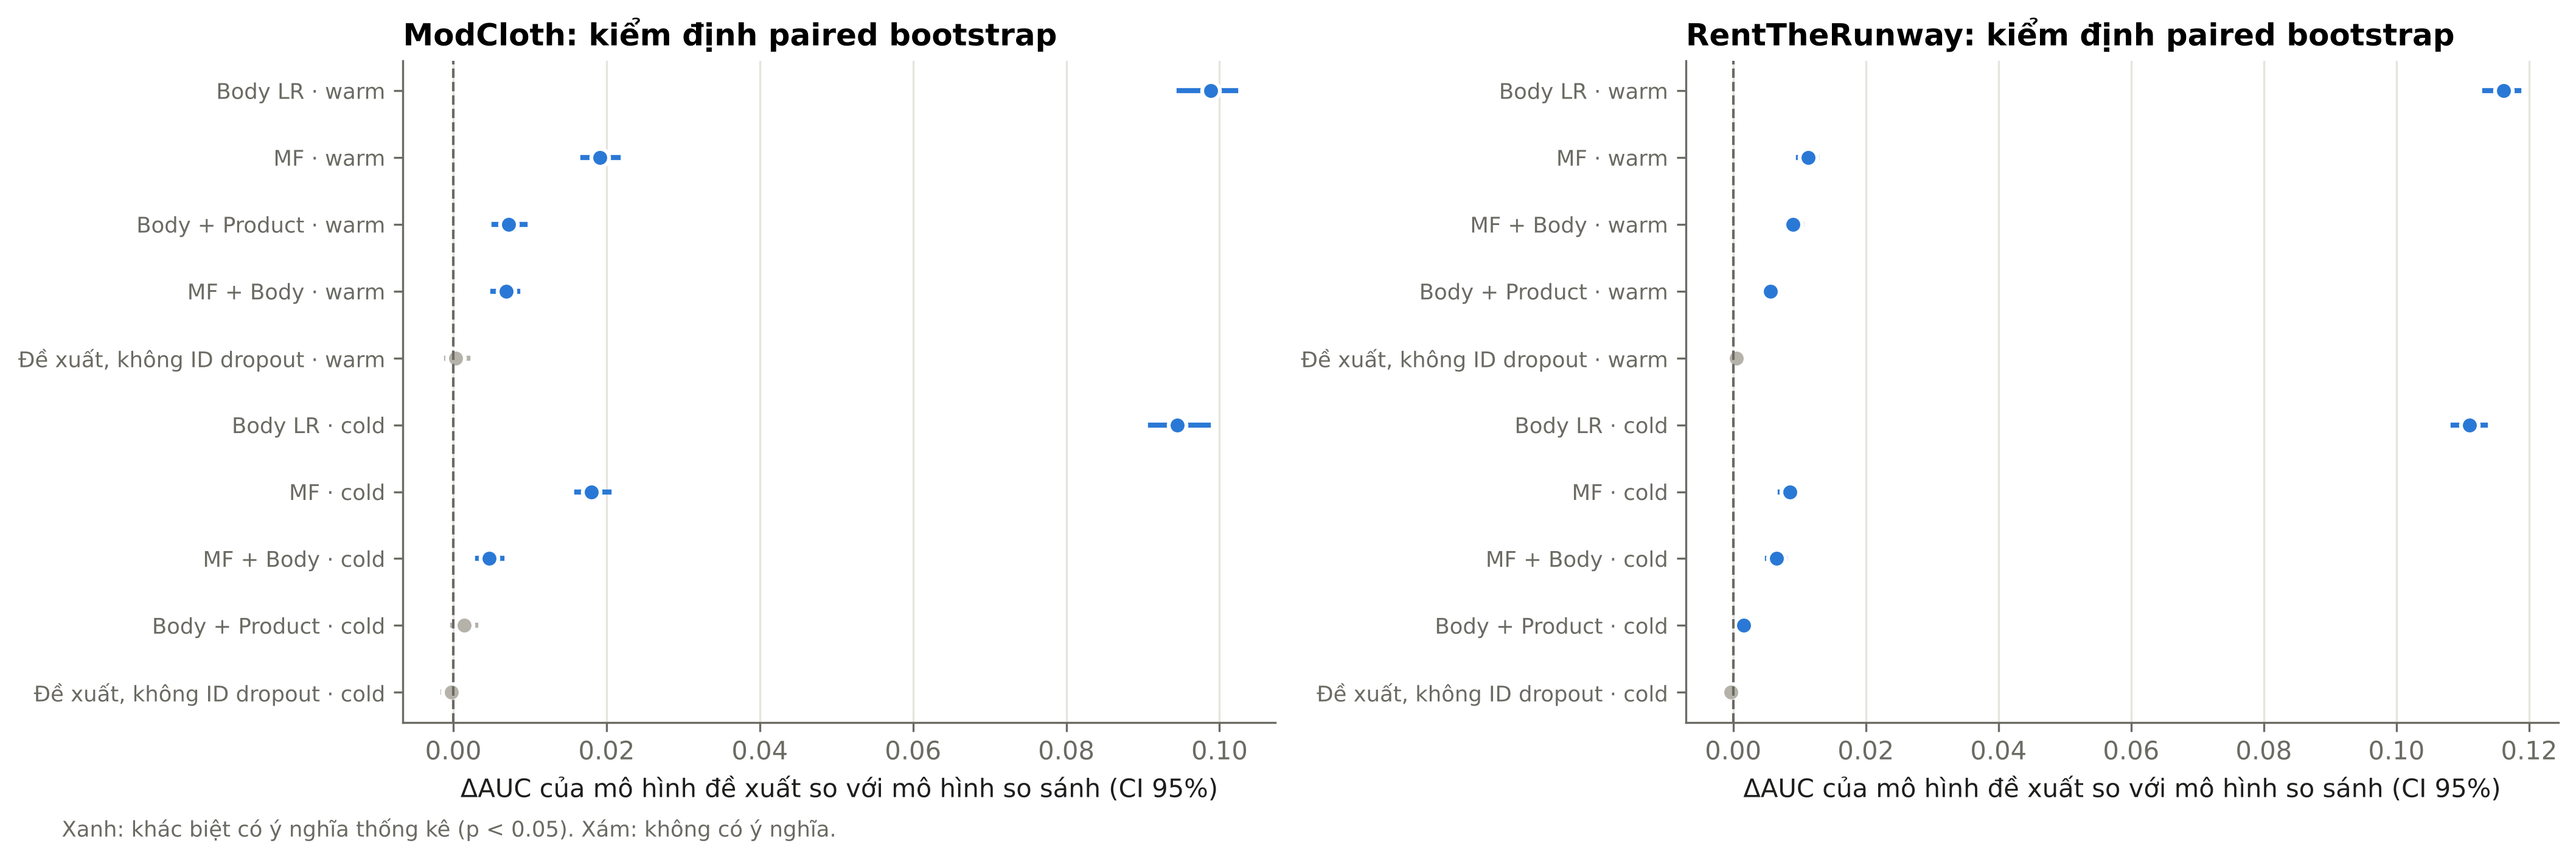

In [10]:
for ds in ["modcloth", "rtr"]:
    g = pd.read_csv(os.path.join(RES, "experiment", ds, "significance.csv"))
    g = g[(g.bucket.astype(str) == "all") & (g.vs != "majority")]
    display(Markdown(f"**{ds}**")); display(g[["protocol", "vs", "delta_auc", "ci95_low", "ci95_high", "p_bootstrap", "p_ttest", "significant"]].round(4))
display(Image(os.path.join(RES, "figures", "fig4_significance_delta_auc.png"), width=900))

## 4. Đánh giá đề xuất size

Trên các giao dịch "fit" của tập test: tỉ lệ đề xuất trùng đúng size khách mặc vừa, và lệch không quá 1 size.

exact_mean        within_1_mean       
protocol               cold   warm          cold   warm
dataset  method                                        
modcloth body         0.440  0.440         0.880  0.877
         hybrid       0.440  0.510         0.880  0.917
         popular      0.255  0.255         0.624  0.624
rtr      body         0.401  0.397         0.791  0.790
         hybrid       0.401  0.445         0.791  0.823
         popular      0.207  0.209         0.513  0.515

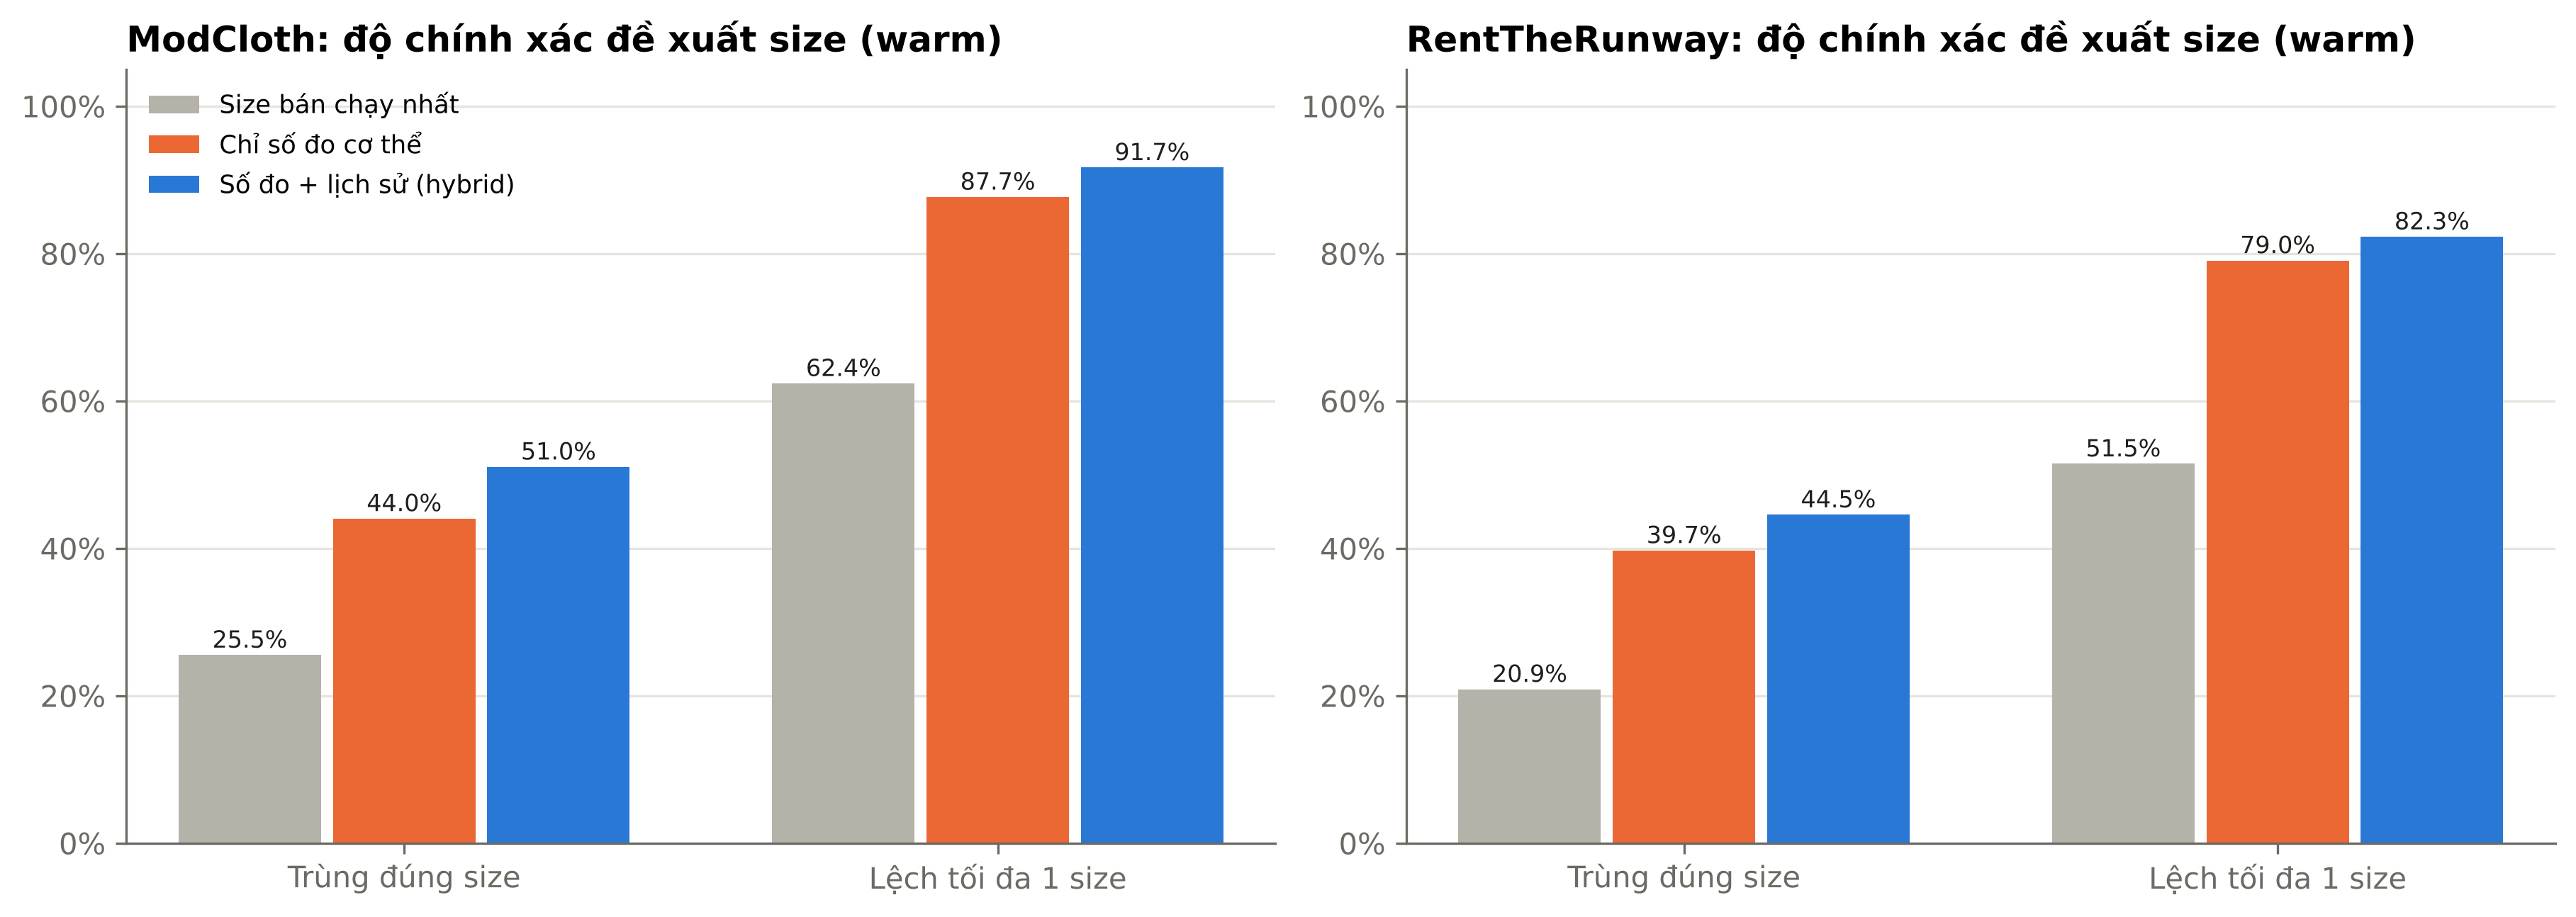

In [11]:
sr = pd.concat([pd.read_csv(os.path.join(RES, "experiment", ds, "size_rec_summary.csv")) for ds in ["modcloth", "rtr"]])
display(sr.pivot_table(index=["dataset", "method"], columns="protocol", values=["exact_mean", "within_1_mean"]).round(3))
display(Image(os.path.join(RES, "figures", "fig5_size_recommendation.png"), width=900))

## 5. Demo gợi ý size

Dùng mô hình đã huấn luyện `04-results/models/rtr.pt` (lệnh `sizerec train`).

In [12]:
from sizerec.trainer import Bundle
from sizerec.recommend import recommend
b = Bundle(os.path.join(RES, "models", "rtr.pt"))

def show(r):
    e = r["size_estimate"]
    print(f"Sản phẩm {r['item_id']} ({r['category']}) · {r['user_status']}")
    print(f"Size mục tiêu = nền theo số đo {e['base_body']:.2f}"
          + (f", nền theo lịch sử {e['user_base']:.2f} (trọng số {e['user_weight']:.2f})" if e['user_base'] is not None else "")
          + f" + danh mục {e['category_offset']:+.2f} + sản phẩm {e['item_offset']:+.2f} = {e['target']:.2f}")
    print(f"→ Size đề xuất: {r['recommended_size']:g} · P(vừa) {r['fit_probability']:.1%}, P(chật) {r['risk_small']:.1%}, P(rộng) {r['risk_large']:.1%}")
    if r["advice"]: print("  ", r["advice"])
    return pd.DataFrame(r["ranking"])[["size", "distance", "p_fit", "p_small", "p_large"]].head(5).round(3)

In [13]:
# Khách mới (cold-start): chỉ có số đo tự khai
show(recommend(b, "126335", body_inputs={"height": "165cm", "weight": "57kg", "bust_size": "34b", "age": 22, "body_type": "petite"}))

Sản phẩm 126335 (dress) · người dùng mới (cold-start)
Size mục tiêu = nền theo số đo 6.23 + danh mục +0.28 + sản phẩm +0.59 = 7.10
→ Size đề xuất: 8 · P(vừa) 47.2%, P(chật) 23.3%, P(rộng) 29.5%
   Mô hình hybrid thấy rủi ro RỘNG ở size này hơi cao (29%). Tuy vậy size nhỏ hơn kế tiếp (4) không an toàn hơn (P(vừa) 41%), nên vẫn giữ size 8.


,size,distance,p_fit,p_small,p_large
0,8.0,0.901,0.472,0.233,0.295
1,4.0,3.099,0.406,0.127,0.467
2,12.0,4.901,0.473,0.241,0.286
3,16.0,8.901,0.474,0.256,0.270
4,20.0,12.901,0.460,0.346,0.194


In [14]:
# Khách cũ có 386 giao dịch: dùng thêm lịch sử mua
show(recommend(b, "126335", user_id="691468"))

Sản phẩm 126335 (dress) · đã có lịch sử
Size mục tiêu = nền theo số đo 11.13, nền theo lịch sử 6.82 (trọng số 1.00) + danh mục +0.28 + sản phẩm +0.59 = 7.69
→ Size đề xuất: 8 · P(vừa) 32.4%, P(chật) 7.9%, P(rộng) 59.8%
   Mô hình hybrid thấy rủi ro RỘNG ở size này khá cao (60%). Tuy vậy size nhỏ hơn kế tiếp (4) không an toàn hơn (P(vừa) 17%), nên vẫn giữ size 8.


,size,distance,p_fit,p_small,p_large
0,8.0,0.313,0.324,0.079,0.598
1,4.0,3.687,0.171,0.031,0.797
2,12.0,4.313,0.313,0.074,0.613
3,16.0,8.313,0.343,0.088,0.569
4,20.0,12.313,0.413,0.133,0.454


## Kết luận

- Mô hình đề xuất (MF + số đo cơ thể + đặc trưng sản phẩm) đạt AUC cao nhất ở cả cold-start và warm, vượt có ý nghĩa thống kê so với MF thuần và MF + số đo.
- Phần cộng tác (lịch sử) phát huy rõ khi khách có từ 2 giao dịch trở lên; với khách mới, số đo cơ thể đóng vai trò chính.
- Đề xuất size kết hợp số đo và lịch sử tăng tỉ lệ chọn đúng size từ 21–25% (size bán chạy nhất) lên 45–51%.

Chi tiết xem `01-huongdan.md` và báo cáo trong `05-report`.